# 01 · Ingesta y primer vistazo al DENUE (ZM Querétaro)

**Objetivo:** leer las ediciones del DENUE descargadas, quedarnos con los 4 municipios de la zona metropolitana y producir las tres gráficas del slide 7:

1. Establecimientos por edición
2. Giros de consumo con más establecimientos
3. Mapa de densidad en hexágonos H3

**Antes de correr:** ejecuta `00_descarga_denue.ipynb`, que deja en `data/raw/` un archivo por edición.

## 0. Librerías y rutas

In [19]:
# Si falta alguna: %pip install pandas matplotlib h3 pyarrow
from pathlib import Path
import zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent          # el notebook vive en tesis_queretaro/notebooks
RAW, PROC, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "figures"
for p in (PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

sorted(p.name for p in RAW.iterdir())

['denue_qro_2020-04.parquet',
 'denue_qro_2021-05.parquet',
 'denue_qro_2022-05.parquet',
 'denue_qro_2023-11.parquet',
 'denue_qro_2024-05.parquet',
 'denue_qro_2025-05.parquet',
 'denue_qro_2026-05.parquet']

## 1. Configuración

`EDICIONES_USAR` fija los 7 cortes anuales 2020–2026. El notebook toma de `data/raw/` solo esos archivos, aunque haya otras ediciones descargadas, y avisa si falta alguno.

In [20]:
# Cortes anuales de la tesis (no hay 05/2023; se usa 11/2023)
EDICIONES_USAR = ["2020-04", "2021-05", "2022-05", "2023-11", "2024-05", "2025-05", "2026-05"]

disponibles = {p.stem.replace("denue_qro_", ""): p.name for p in sorted(RAW.glob("denue_qro_*.parquet"))}
faltan = [e for e in EDICIONES_USAR if e not in disponibles]
if faltan:
    print("Aviso, faltan estas ediciones (córrelas en el notebook 00):", faltan)
EDICIONES = {e: disponibles[e] for e in EDICIONES_USAR if e in disponibles}
if not EDICIONES:
    raise FileNotFoundError(f"No hay ediciones en {RAW}. Corre primero 00_descarga_denue.ipynb.")
print(EDICIONES)

MUNICIPIOS_ZMQ = {6: "Corregidora", 8: "Huimilpan", 11: "El Marqués", 14: "Querétaro"}

# Giros de consumo (prefijos SCIAN) que serán variables objetivo
PREFIJOS_CONSUMO = ("46", "722", "811", "812", "621", "7139")
UMBRAL_GIRO = 100   # mínimo de establecimientos para quedarse a 4 dígitos

{'2020-04': 'denue_qro_2020-04.parquet', '2021-05': 'denue_qro_2021-05.parquet', '2022-05': 'denue_qro_2022-05.parquet', '2023-11': 'denue_qro_2023-11.parquet', '2024-05': 'denue_qro_2024-05.parquet', '2025-05': 'denue_qro_2025-05.parquet', '2026-05': 'denue_qro_2026-05.parquet'}


## 2. Función de lectura

Lee el Parquet que deja el notebook 00 y, por si descargaste a mano, también zip o csv. Para esos casos absorbe los cambios de formato entre ediciones:

- Abre el zip directo, sin descomprimir, y toma el CSV más grande que contenga.
- Prueba `utf-8` y luego `latin-1`.
- Pasa los nombres de columna a minúsculas.
- Lee los códigos como texto para no perder ceros a la izquierda.

In [21]:
COLS = ["id", "clee", "nom_estab", "codigo_act", "nombre_act", "per_ocu",
        "cve_ent", "cve_mun", "municipio", "ageb", "manzana",
        "latitud", "longitud", "fecha_alta"]

def _leer_csv(buffer_bytes):
    for enc in ("utf-8", "latin-1"):
        try:
            df = pd.read_csv(io.BytesIO(buffer_bytes), encoding=enc, dtype=str, low_memory=False)
            break
        except UnicodeDecodeError:
            continue
    df.columns = df.columns.str.strip().str.lower()
    faltan = [c for c in COLS if c not in df.columns]
    if faltan:
        print("  Aviso, columnas no encontradas:", faltan)
    return df[[c for c in COLS if c in df.columns]]

def leer_denue(ruta: Path) -> pd.DataFrame:
    if ruta.suffix.lower() == ".parquet":
        df = pd.read_parquet(ruta)
        df.columns = df.columns.str.strip().str.lower()
        return df[[c for c in COLS if c in df.columns]]
    if ruta.suffix.lower() == ".zip":
        with zipfile.ZipFile(ruta) as z:
            csvs = [i for i in z.infolist() if i.filename.lower().endswith(".csv")]
            mayor = max(csvs, key=lambda i: i.file_size)   # el conjunto de datos, no los diccionarios
            print(f"  {ruta.name} → {mayor.filename}")
            return _leer_csv(z.read(mayor))
    return _leer_csv(ruta.read_bytes())

## 3. Leer, filtrar y guardar

Por edición:

1. Filtra el estado 22 y los 4 municipios.
2. Quita administración pública (SCIAN 93).
3. Limpia las coordenadas.
4. Guarda en Parquet, o en CSV si no tienes `pyarrow`.

In [22]:
# Caja geográfica de la ZM de Querétaro (lat, lon); fuera de ella = error de georreferencia
LAT_MIN, LAT_MAX = 20.2, 21.0
LON_MIN, LON_MAX = -100.7, -99.9

def preparar(df, etiqueta):
    df = df.copy()
    df["cve_ent"] = pd.to_numeric(df["cve_ent"], errors="coerce")
    df["cve_mun"] = pd.to_numeric(df["cve_mun"], errors="coerce")
    df = df[(df["cve_ent"] == 22) & (df["cve_mun"].isin(MUNICIPIOS_ZMQ))]
    df["codigo_act"] = df["codigo_act"].str.strip().str.zfill(6)
    df = df[~df["codigo_act"].str.startswith("93")]
    df["latitud"] = pd.to_numeric(df["latitud"], errors="coerce")
    df["longitud"] = pd.to_numeric(df["longitud"], errors="coerce")

    dentro = df["latitud"].between(LAT_MIN, LAT_MAX) & df["longitud"].between(LON_MIN, LON_MAX)
    descartados = df.loc[~dentro, ["id", "nom_estab", "municipio", "latitud", "longitud"]].assign(edicion=etiqueta)
    if len(descartados):
        print(f"  {etiqueta}: {len(descartados)} registros con coordenadas fuera de la ZM, descartados")
    df = df[dentro]

    df["edicion"] = etiqueta
    df["mun_nombre"] = df["cve_mun"].map(MUNICIPIOS_ZMQ)
    return df, descartados

frames, fuera = [], []
for etiqueta, archivo in sorted(EDICIONES.items()):
    print("Leyendo", etiqueta)
    df, desc = preparar(leer_denue(RAW / archivo), etiqueta)
    try:
        df.to_parquet(PROC / f"denue_zmq_{etiqueta}.parquet", index=False)
    except ImportError:
        df.to_csv(PROC / f"denue_zmq_{etiqueta}.csv", index=False)
    frames.append(df)
    fuera.append(desc)

denue = pd.concat(frames, ignore_index=True)
fuera_zm = pd.concat(fuera, ignore_index=True)
fuera_zm.to_csv(PROC / "registros_fuera_de_zm.csv", index=False)   # bitácora para el objetivo 1

print(f"\nTotal descartados por coordenadas: {len(fuera_zm)}")
denue.groupby("edicion").size()

Leyendo 2020-04
Leyendo 2021-05
  2021-05: 7 registros con coordenadas fuera de la ZM, descartados
Leyendo 2022-05
Leyendo 2023-11
Leyendo 2024-05
Leyendo 2025-05
Leyendo 2026-05
  2026-05: 1 registros con coordenadas fuera de la ZM, descartados

Total descartados por coordenadas: 8


edicion
2020-04    61667
2021-05    62022
2022-05    62482
2023-11    63155
2024-05    63600
2025-05    69783
2026-05    70612
dtype: int64

## 4. Calidad básica por edición

Antes de graficar, revisa cuántos registros traen coordenadas inválidas y cuántos `id` se repiten dentro de una misma edición.

In [23]:
calidad = denue.groupby("edicion").agg(
    registros=("id", "size"),
    ids_unicos=("id", "nunique"),
    sin_coordenadas=("latitud", lambda s: s.isna().sum()),
    fecha_alta_max=("fecha_alta", "max"),
)
calidad

,registros,ids_unicos,sin_coordenadas,fecha_alta_max
edicion,,,,
2020-04,61667,61667,0,2020-04
2021-05,62022,62022,0,2021-05
2022-05,62482,62482,0,2022-05
2023-11,63155,63155,0,2023-11
2024-05,63600,63600,0,2024-05
2025-05,69783,69783,0,2025-05
2026-05,70612,70612,0,2026-04


## 5. Gráfica 1 · Establecimientos por edición y municipio

mun_nombre  Querétaro  El Marqués  Corregidora  Huimilpan  Total
edicion                                                         
2020-04         50423        4426         6256        562  61667
2021-05         50664        4479         6315        564  62022
2022-05         51064        4516         6338        564  62482
2023-11         51406        4722         6452        575  63155
2024-05         51680        4789         6534        597  63600
2025-05         53986        6946         8168        683  69783
2026-05         54607        7086         8224        695  70612


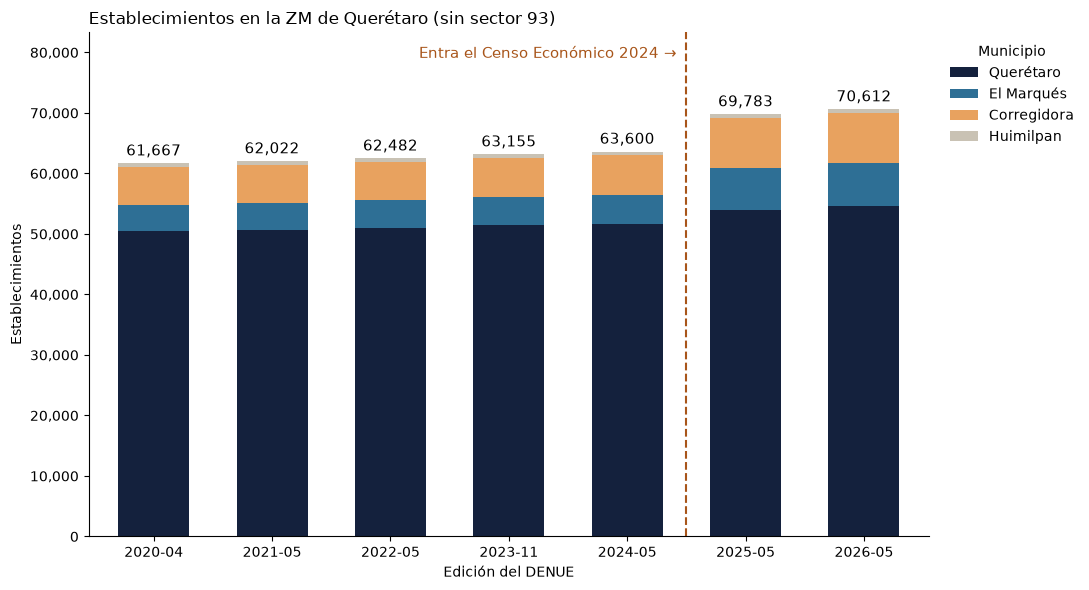

In [24]:
from matplotlib.ticker import FuncFormatter

tabla = (denue.groupby(["edicion", "mun_nombre"]).size()
              .unstack(fill_value=0)[["Querétaro", "El Marqués", "Corregidora", "Huimilpan"]])
tot = tabla.sum(axis=1)
print(tabla.assign(Total=tot))

fig, ax = plt.subplots(figsize=(11, 6))
tabla.plot(kind="bar", stacked=True, ax=ax, width=0.6,
           color=["#14213D", "#2E6F95", "#E8A25F", "#C9C2B4"])
ax.set_ylim(0, tot.max() * 1.18)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Edición del DENUE"); ax.set_ylabel("Establecimientos")
ax.set_title("Establecimientos en la ZM de Querétaro (sin sector 93)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Municipio", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

for i, t in enumerate(tot):
    ax.text(i, t + tot.max() * 0.01, f"{t:,}", ha="center", va="bottom", fontsize=11)

if {"2024-05", "2025-05"} <= set(tabla.index):
    x = list(tabla.index).index("2024-05") + 0.5
    ax.axvline(x, color="#A8551A", linestyle="--", linewidth=1.5)
    ax.text(x - 0.08, tot.max() * 1.13, "Entra el Censo Económico 2024 →",
            color="#A8551A", fontsize=11, ha="right", va="center")

plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG / "01_establecimientos_por_edicion.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Gráfica 2 · Giros de consumo con más establecimientos

Agrupa a 4 dígitos del SCIAN los giros de consumo en la **primera** edición y marca cuáles pasan el umbral.

**Ojo:** las ediciones posteriores a 11/2024 usan SCIAN 2023. Para comparar giros entre ediciones hará falta la tabla de correspondencia; aquí solo miramos una edición.

Giros a 4 dígitos: 41 · pasan el umbral de 100: 34


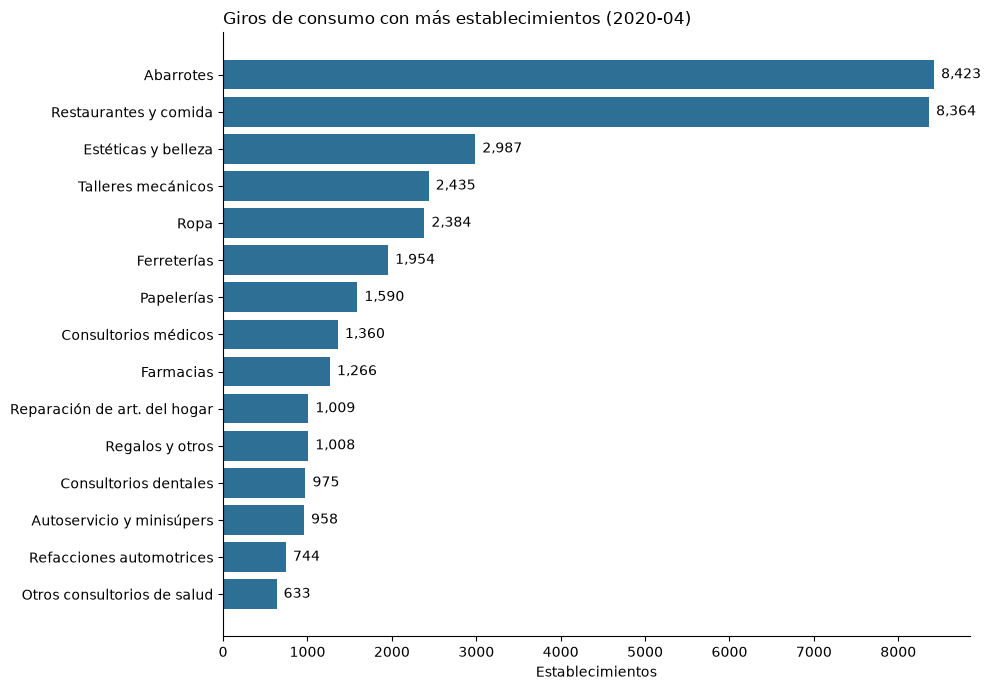

,giro4,n,nombre_act,etiqueta,pasa_umbral
0,4611,8423,"Comercio al por menor en tiendas de abarrotes,...",Abarrotes,True
1,7225,8364,Restaurantes con servicio de preparación de an...,Restaurantes y comida,True
2,8121,2987,Salones y clínicas de belleza y peluquerías,Estéticas y belleza,True
3,8111,2435,Reparación mecánica en general de automóviles ...,Talleres mecánicos,True
4,4632,2384,"Comercio al por menor de ropa, excepto de bebé...",Ropa,True
5,4671,1954,Comercio al por menor en ferreterías y tlapale...,Ferreterías,True
6,4653,1590,Comercio al por menor de artículos de papelería,Papelerías,True
7,6211,1360,Consultorios de medicina especializada del sec...,Consultorios médicos,True
8,4641,1266,Farmacias sin minisúper,Farmacias,True
9,8114,1009,Reparación y mantenimiento de otros artículos ...,Reparación de art. del hogar,True


In [25]:
import textwrap

# A: nombres cortos para la presentación
ETIQUETAS = {
    "4611": "Abarrotes", "7225": "Restaurantes y comida", "8121": "Estéticas y belleza",
    "8111": "Talleres mecánicos", "4632": "Ropa", "4671": "Ferreterías", "4653": "Papelerías",
    "6211": "Consultorios médicos", "4641": "Farmacias", "8114": "Reparación de art. del hogar",
    "4659": "Regalos y otros", "6212": "Consultorios dentales", "4621": "Autoservicio y minisúpers",
    "4682": "Refacciones automotrices", "6213": "Otros consultorios de salud",
}

# B: si el giro no está en el diccionario, limpia el nombre automáticamente
def limpiar(nombre):
    for pref in ("Comercio al por menor en tiendas de ", "Comercio al por menor de ",
                 "Comercio al por menor en "):
        nombre = nombre.replace(pref, "")
    nombre = nombre.replace(" del sector privado", "")
    return textwrap.shorten(nombre[0].upper() + nombre[1:], width=34, placeholder="…")

base = denue[denue["edicion"] == min(EDICIONES)]
consumo = base[base["codigo_act"].str.startswith(PREFIJOS_CONSUMO)].copy()
consumo["giro4"] = consumo["codigo_act"].str[:4]
nombre = consumo.groupby("giro4")["nombre_act"].agg(lambda s: s.value_counts().index[0])
giros = (consumo.groupby("giro4").size().rename("n").to_frame()
                .join(nombre).sort_values("n", ascending=False).reset_index())
giros["etiqueta"] = [ETIQUETAS.get(g, limpiar(n)) for g, n in zip(giros["giro4"], giros["nombre_act"])]
giros["pasa_umbral"] = giros["n"] >= UMBRAL_GIRO
print(f"Giros a 4 dígitos: {len(giros)} · pasan el umbral de {UMBRAL_GIRO}: {giros['pasa_umbral'].sum()}")

top = giros.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["etiqueta"], top["n"], color="#2E6F95")
for y, n in enumerate(top["n"]):
    ax.text(n + giros["n"].max() * 0.01, y, f"{n:,}", va="center", fontsize=10)
ax.set_xlabel("Establecimientos"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Giros de consumo con más establecimientos ({min(EDICIONES)})", loc="left")
plt.tight_layout(); plt.savefig(FIG / "02_top_giros_consumo.png", dpi=200, bbox_inches="tight"); plt.show()
giros.head(20)

## 7. Gráfica 3 · Mapa de densidad en hexágonos H3

Asigna cada establecimiento a un hexágono de resolución 8 (unos 0.74 km²) y colorea por número de establecimientos, en escala logarítmica porque el centro concentra muchísimos más.

Hay dos formas de dibujarlo:

- **A (aquí):** imagen estática con matplotlib, lista para el slide.
- **B (opcional, al final):** mapa interactivo con `folium`, útil para explorar.

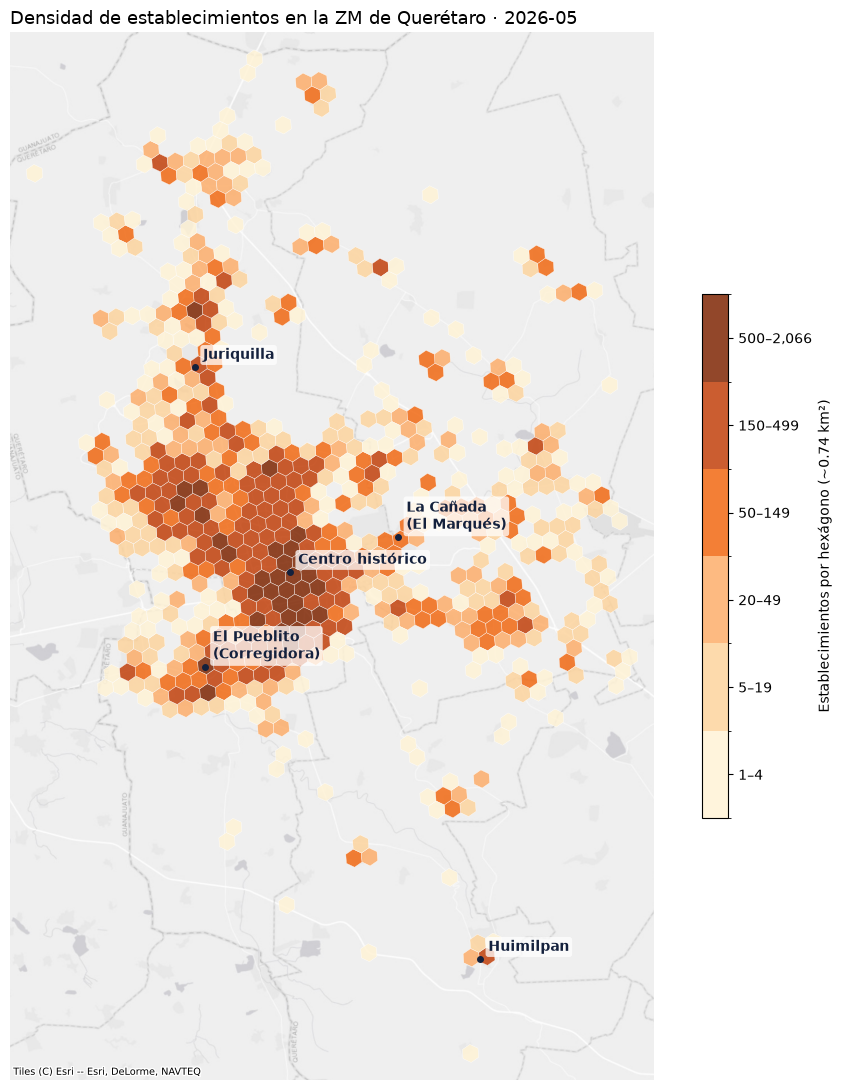

Hexágonos con al menos un negocio: 657 · mediana: 23 · máximo: 2,066


In [30]:
import h3
import contextily as ctx
from matplotlib.collections import PolyCollection
from matplotlib.colors import BoundaryNorm, ListedColormap

RES = 8
ult = denue[denue["edicion"] == max(EDICIONES)].dropna(subset=["latitud", "longitud"])
ult = ult.assign(h3=[h3.latlng_to_cell(la, lo, RES) for la, lo in zip(ult["latitud"], ult["longitud"])])
conteo = ult.groupby("h3").size()

# Clases legibles en lugar de escala log continua
BORDES = [1, 5, 20, 50, 150, 500, conteo.max() + 1]
ETIQ = ["1–4", "5–19", "20–49", "50–149", "150–499", f"500–{conteo.max():,}"]
cmap = ListedColormap(["#FFF3D6", "#FDD49E", "#FDAE6B", "#F16913", "#C2410C", "#7F2704"])
norm = BoundaryNorm(BORDES, cmap.N)

polys = [[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in conteo.index]
xs = [x for p in polys for x, _ in p]
ys = [y for p in polys for _, y in p]
pad = 0.01

fig, ax = plt.subplots(figsize=(10, 11))
ax.set_xlim(min(xs) - pad, max(xs) + pad)
ax.set_ylim(min(ys) - pad, max(ys) + pad)
ax.set_aspect(1 / np.cos(np.radians(20.6)))

# Mapa base gris (Esri, sin API key); se dibuja debajo de los hexágonos
ctx.add_basemap(ax, crs="EPSG:4326", source=ctx.providers.Esri.WorldGrayCanvas,
                zoom=12, attribution_size=7)

coll = PolyCollection(polys, array=conteo.values, cmap=cmap, norm=norm,
                      edgecolor="white", linewidth=0.3, alpha=0.85)
ax.add_collection(coll)

# Referencias para ubicarse
REFERENCIAS = {
    "Centro histórico": (20.593, -100.392),
    "Juriquilla": (20.710, -100.450),
    "El Pueblito\n(Corregidora)": (20.539, -100.444),
    "La Cañada\n(El Marqués)": (20.613, -100.326),
    "Huimilpan": (20.372, -100.276),
}
for nombre, (la, lo) in REFERENCIAS.items():
    ax.plot(lo, la, "o", ms=4, color="#14213D")
    ax.annotate(nombre, (lo, la), xytext=(6, 6), textcoords="offset points", fontsize=10,
                color="#14213D", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.75))

cbar = fig.colorbar(coll, ax=ax, shrink=0.5, ticks=[(a + b) / 2 for a, b in zip(BORDES[:-1], BORDES[1:])])
cbar.ax.set_yticklabels(ETIQ)
cbar.set_label("Establecimientos por hexágono (~0.74 km²)")
ax.set_axis_off()
ax.set_title(f"Densidad de establecimientos en la ZM de Querétaro · {max(EDICIONES)}", loc="left", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "03_mapa_h3.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Hexágonos con al menos un negocio: {len(conteo):,} · mediana: {conteo.median():.0f} · máximo: {conteo.max():,}")

### 7b. (Opcional) Mapa interactivo con folium

In [27]:
# Versión interactiva
import folium
from matplotlib.colors import to_hex
m = folium.Map(location=[20.6, -100.4], zoom_start=11, tiles="OpenStreetMap")   # ← sin API key
vmax = np.log1p(conteo.max())
for c, n in conteo.items():
    folium.Polygon(h3.cell_to_boundary(c), weight=0, fill=True, fill_opacity=0.7,
                   fill_color=to_hex(plt.cm.YlOrBr(np.log1p(n) / vmax)),
                   tooltip=f"{n} establecimientos").add_to(m)
m.save(FIG / "03_mapa_h3_interactivo.html")

## 8. Números para el slide 7

Copia esta salida al slide: total por edición, cambio entre la primera y la última edición, y cuántos giros pasan el umbral.

In [28]:
tot = denue.groupby("edicion").size()
print("Total por edición:"); print(tot.to_string())
if len(tot) > 1:
    print(f"Cambio {tot.index[0]} → {tot.index[-1]}: {tot.iloc[-1] - tot.iloc[0]:+,} ({tot.iloc[-1] / tot.iloc[0] - 1:+.1%})")
print(f"Giros de consumo a 4 dígitos que pasan el umbral: {giros['pasa_umbral'].sum()} de {len(giros)}")

Total por edición:
edicion
2020-04    61667
2021-05    62022
2022-05    62482
2023-11    63155
2024-05    63600
2025-05    69783
2026-05    70612
Cambio 2020-04 → 2026-05: +8,945 (+14.5%)
Giros de consumo a 4 dígitos que pasan el umbral: 34 de 41
